In [1]:
import cv2
import h5py
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm as c
from keras.models import model_from_json

In [2]:
def load_model():
    # Function to load and return neural network model 
    json_file = open(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\Sem 8 Project\CSRnet-master\models\Model.json", 'r')
    loaded_model_json = json_file.read()
    json_file.close()
    loaded_model = model_from_json(loaded_model_json)
    loaded_model.load_weights(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\Sem 8 Project\CSRnet-master\weights\model_B_weights.h5")
    return loaded_model

def create_img(path):
    #Function to load,normalize and return image 
    print(path)
    im = Image.open(path).convert('RGB')
    
    im = np.array(im)
    
    im = im/255.0
    
    im[:,:,0]=(im[:,:,0]-0.485)/0.229
    im[:,:,1]=(im[:,:,1]-0.456)/0.224
    im[:,:,2]=(im[:,:,2]-0.406)/0.225


    im = np.expand_dims(im,axis  = 0)
    return im

In [3]:
def predict(path):
    #Function to load image,predict heat map, generate count and return (count , image , heat map)
    model = load_model()
    image = create_img(path)
    ans = model.predict(image)
    count = np.sum(ans)
    return count,image,ans

In [4]:
ans,img,hmap = predict(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\train_data\images\IMG_150.jpg")

C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\train_data\images\IMG_150.jpg
1/1 [==============================] - 4s 4s/step


In [5]:
print(ans,"this is ans",hmap)

90.163635 this is ans [[[[0.00231688]
   [0.00197327]
   [0.        ]
   ...
   [0.00264591]
   [0.00323669]
   [0.00287055]]

  [[0.00329909]
   [0.00304259]
   [0.00093949]
   ...
   [0.00243836]
   [0.00272555]
   [0.0012776 ]]

  [[0.00447331]
   [0.00316149]
   [0.00092778]
   ...
   [0.00324342]
   [0.00287284]
   [0.0031889 ]]

  ...

  [[0.00906895]
   [0.00307721]
   [0.00645614]
   ...
   [0.00018465]
   [0.0006762 ]
   [0.00063478]]

  [[0.00184936]
   [0.00128496]
   [0.00284339]
   ...
   [0.0008346 ]
   [0.00027463]
   [0.00081586]]

  [[0.00375358]
   [0.00148483]
   [0.00269043]
   ...
   [0.00088986]
   [0.00032843]
   [0.00052919]]]]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


90.163635


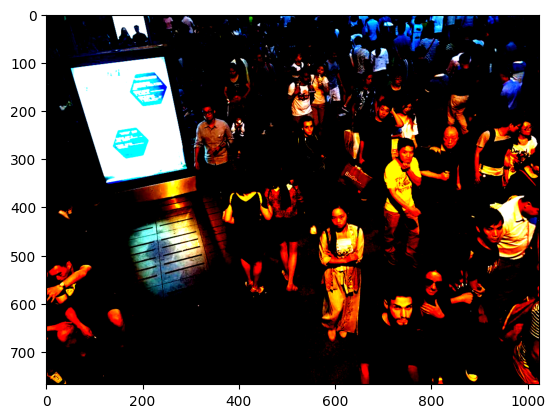

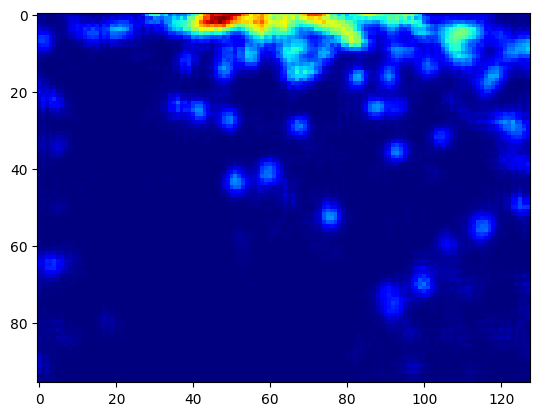

In [6]:
print(ans)
#Print count, image, heat map
plt.imshow(img.reshape(img.shape[1],img.shape[2],img.shape[3]))
plt.show()
plt.imshow(hmap.reshape(hmap.shape[1],hmap.shape[2]) , cmap = c.jet )
plt.show()

Original Count :  294


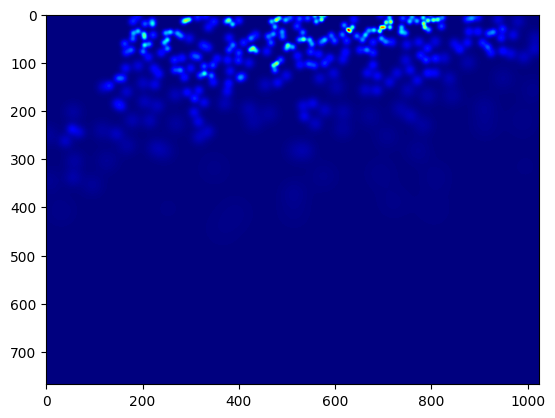

In [7]:
temp = h5py.File(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground\IMG_170.h5" , 'r')
temp_1 = np.asarray(temp['density'])
plt.imshow(temp_1,cmap = c.jet)
print("Original Count : ",int(np.sum(temp_1)) + 1)

Original Count :  179


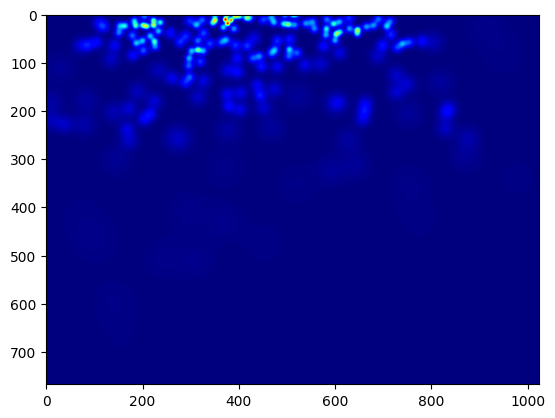

In [8]:
temp = h5py.File(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground\IMG_114.h5" , 'r')
temp_1 = np.asarray(temp['density'])
plt.imshow(temp_1,cmap = c.jet)
print("Original Count : ",int(np.sum(temp_1)) + 1)

C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images\IMG_114.jpg
1/1 [==============================] - 3s 3s/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


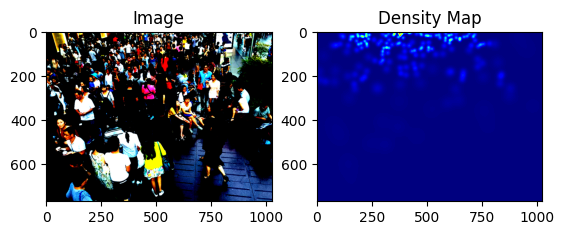

Original Count :  179


In [9]:
# Load and predict for a single image
image_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images\IMG_114.jpg"
count, image, heat_map = predict(image_path)

# Display image
plt.subplot(1, 2, 1)
plt.imshow(image.reshape(image.shape[1], image.shape[2], image.shape[3]))
plt.title('Image')

# Load density map
density_map_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground\IMG_114.h5"
with h5py.File(density_map_path, 'r') as file:
    density_map = np.array(file['density'])

# Display density map
plt.subplot(1, 2, 2)
plt.imshow(density_map, cmap=c.jet)
plt.title('Density Map')

plt.show()
print("Original Count : ", int(np.sum(density_map)) + 1)

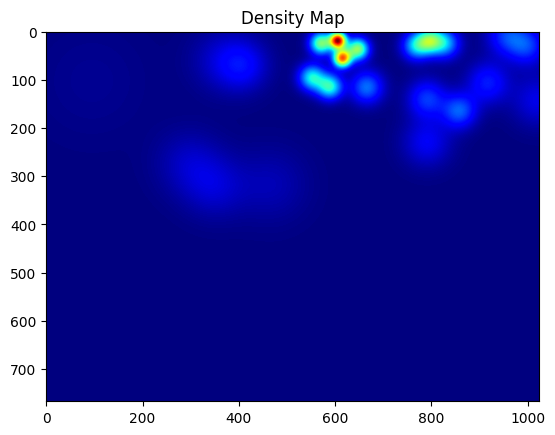

Original Count: 22


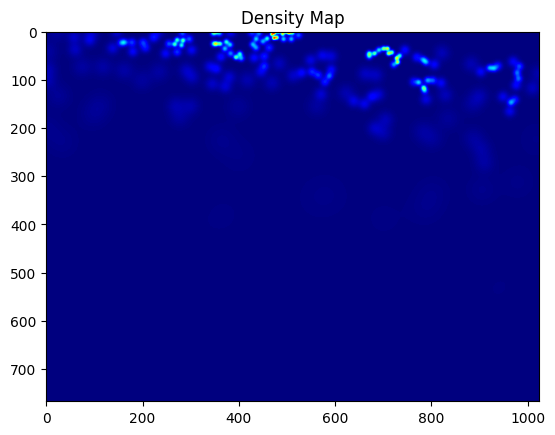

Original Count: 173


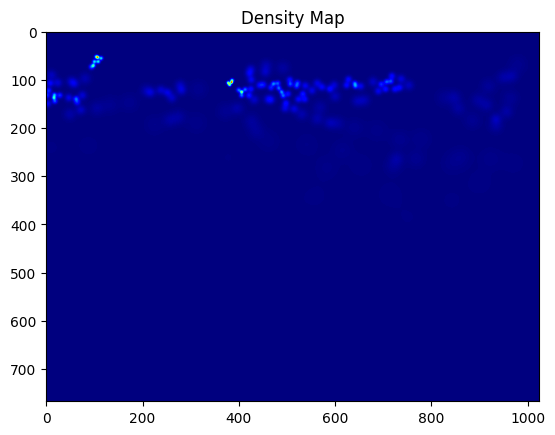

Original Count: 157


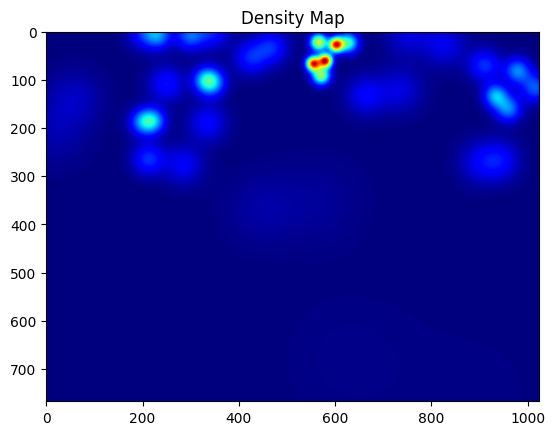

Original Count: 34


In [10]:
import os

# Path to the folder containing the images
folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
file_names = os.listdir(folder_path)

# Display count and density map for the first four images
for i in range(4):
    file_name = file_names[i]
    file_path = os.path.join(folder_path, file_name)
    
    # Load density map
    temp = h5py.File(file_path, 'r')
    temp_1 = np.asarray(temp['density'])
    
    # Display density map
    plt.imshow(temp_1, cmap=c.jet)
    plt.title("Density Map")
    plt.show()
    
    # Display original count
    original_count = int(np.sum(temp_1)) + 1
    print("Original Count:", original_count)


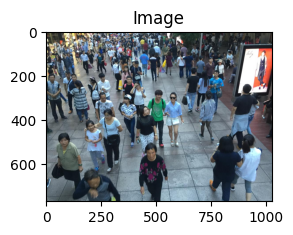

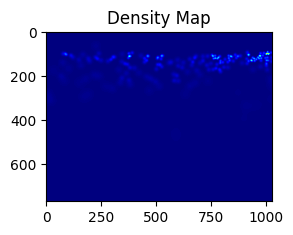

Original Count: 189


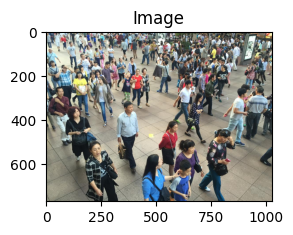

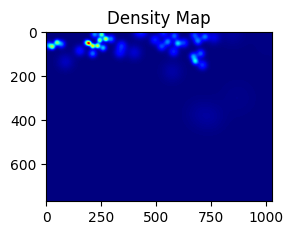

Original Count: 42


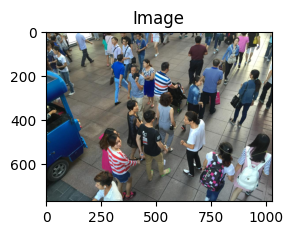

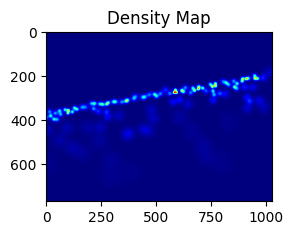

Original Count: 113


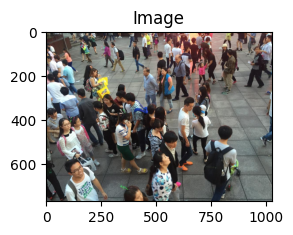

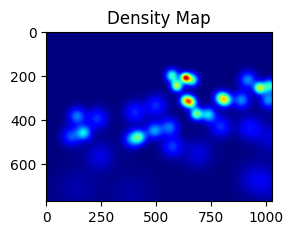

Original Count: 33


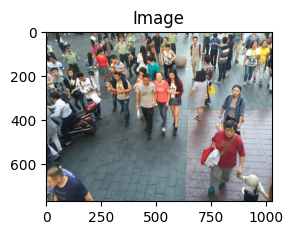

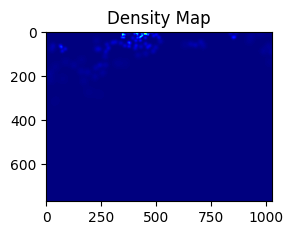

Original Count: 103


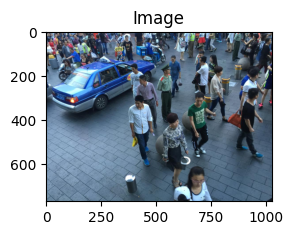

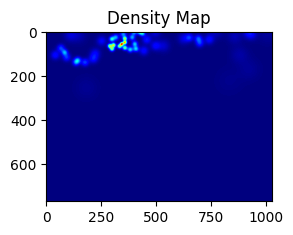

Original Count: 46


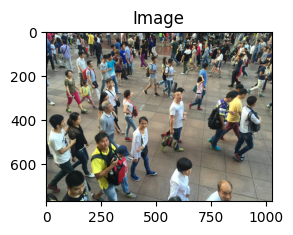

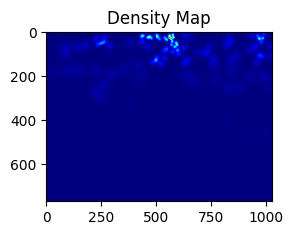

Original Count: 93


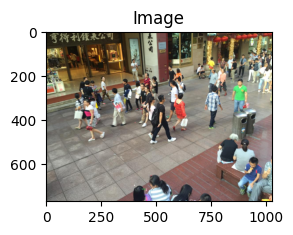

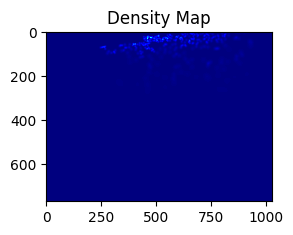

Original Count: 321


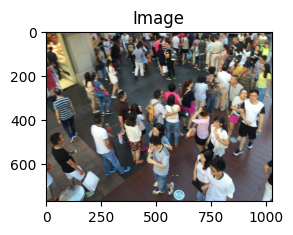

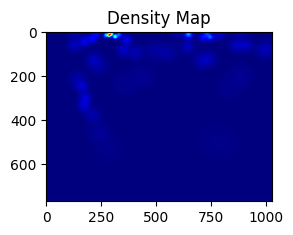

Original Count: 43


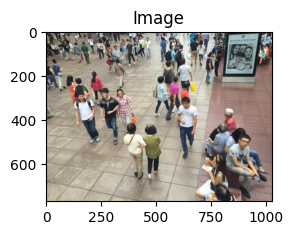

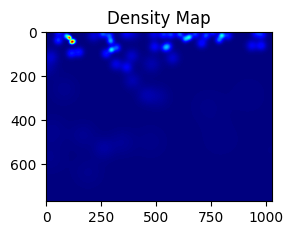

Original Count: 54


In [12]:
import os
import cv2
import random

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Shuffle the list of file names
random.shuffle(image_file_names)
random.shuffle(density_file_names)

# Display images and density maps for the first four images
for i in range(10):
    # Load image
    plt.subplot(1, 2, 1)
    image_file_name = image_file_names[i]
    image_file_path = os.path.join(image_folder_path, image_file_name)
    image = cv2.imread(image_file_path)
    
    # Load density map
    density_file_name = density_file_names[i]
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    
    # Display image
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image")
    plt.show()
    
    # Display density map
    plt.subplot(1, 2, 2)
    plt.imshow(density_map, cmap='jet')
    plt.title("Density Map")
    plt.show()
    
    # Display original count
    original_count = int(np.sum(density_map)) + 1
    print("Original Count:", original_count)


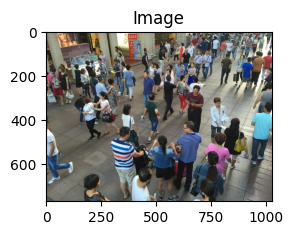

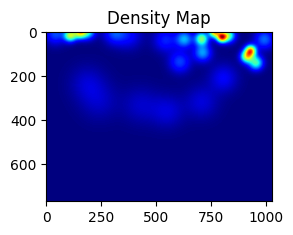

Original Count: 21
Category: Safe


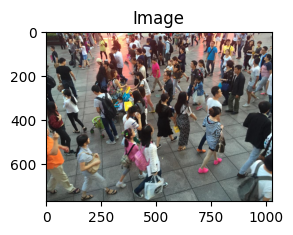

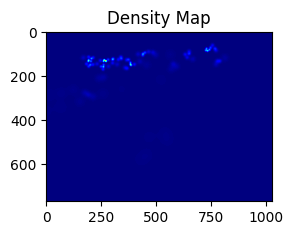

Original Count: 92
Category: Safe


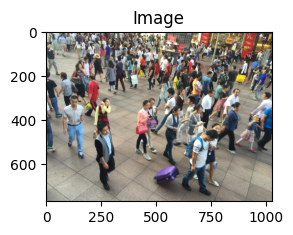

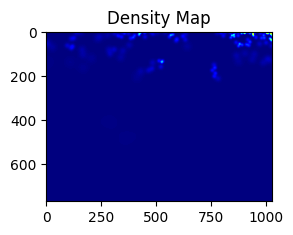

Original Count: 125
Category: Safe


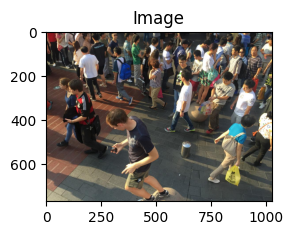

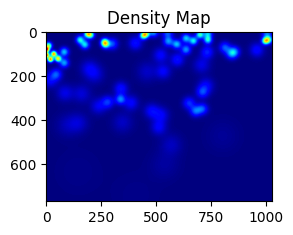

Original Count: 65
Category: Safe


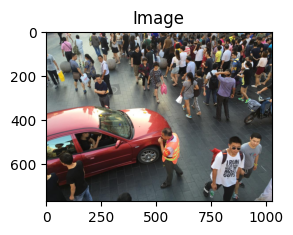

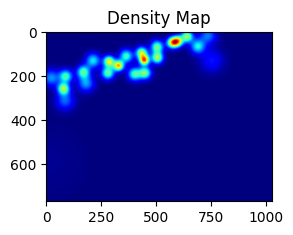

Original Count: 24
Category: Safe


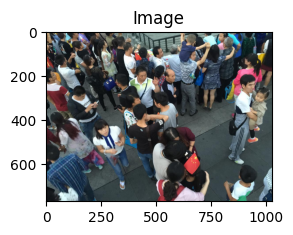

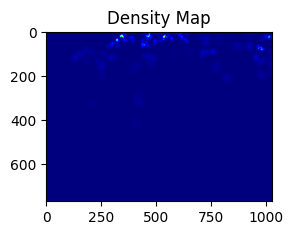

Original Count: 126
Category: Safe


In [16]:
import os
import cv2
import random

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Shuffle the list of file names
random.shuffle(image_file_names)
random.shuffle(density_file_names)

# Define a threshold count
threshold_count = 200  # Adjust this value based on your requirement

# Display images and density maps for the first four images
for i in range(6):
    # Load image
    plt.subplot(1, 2, 1)
    image_file_name = image_file_names[i]
    image_file_path = os.path.join(image_folder_path, image_file_name)
    image = cv2.imread(image_file_path)
    
    # Load density map
    density_file_name = density_file_names[i]
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    
    # Display image
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image")
    plt.show()
    
    # Display density map
    plt.subplot(1, 2, 2)
    plt.imshow(density_map, cmap='jet')
    plt.title("Density Map")
    plt.show()
    
    # Calculate count
    count = int(np.sum(density_map)) + 1
    
    # Display original count
    print("Original Count:", count)
    
    # Categorize as safe or unsafe
    if count > threshold_count:
        print("Category: Unsafe")
    else:
        print("Category: Safe")


In [2]:
import os
import cv2
import h5py
import numpy as np
import pandas as pd

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Define a threshold count
threshold_count = 200  # Adjust this value based on your requirement

# Initialize lists to store results
image_names = []
counts = []
categories = []

# Iterate over each image and its corresponding density map
for image_file_name, density_file_name in zip(image_file_names, density_file_names):
    # Load image
    image_file_path = os.path.join(image_folder_path, image_file_name)
    image = cv2.imread(image_file_path)
    
    # Load density map
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    
    # Calculate count
    count = int(np.sum(density_map)) + 1
    
    # Categorize as safe or unsafe
    if count > threshold_count:
        category = "Unsafe"
    else:
        category = "Safe"
    
    # Store results
    image_names.append(image_file_name)
    counts.append(count)
    categories.append(category)

# Create DataFrame to store results
results_df = pd.DataFrame({
    "Image Name": image_names,
    "Count": counts,
    "Category": categories
})

# Display results in tabular format
print(results_df)


      Image Name  Count Category
0      IMG_1.jpg     22     Safe
1     IMG_10.jpg    173     Safe
2    IMG_100.jpg    157     Safe
3    IMG_101.jpg     34     Safe
4    IMG_102.jpg     65     Safe
..           ...    ...      ...
311   IMG_95.jpg     45     Safe
312   IMG_96.jpg    207   Unsafe
313   IMG_97.jpg    104     Safe
314   IMG_98.jpg    240   Unsafe
315   IMG_99.jpg    112     Safe

[316 rows x 3 columns]


In [3]:
import os
import cv2
import h5py
import numpy as np
import pandas as pd

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Define a threshold count
threshold_count = 1000  # Adjust this value based on your requirement

# Initialize lists to store results
image_names = []
counts = []
categories = []

# Iterate over each image and its corresponding density map
for image_file_name, density_file_name in zip(image_file_names, density_file_names):
    # Load image
    image_file_path = os.path.join(image_folder_path, image_file_name)
    image = cv2.imread(image_file_path)
    
    # Load density map
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    
    # Calculate count
    count = int(np.sum(density_map)) + 1
    
    # Categorize as safe or unsafe
    if count > threshold_count:
        category = "Unsafe"
    else:
        category = "Safe"
    
    # Store results
    image_names.append(image_file_name)
    counts.append(count)
    categories.append(category)

# Create DataFrame to store results
results_df = pd.DataFrame({
    "Image Name": image_names,
    "Count": counts,
    "Category": categories
})

# Display results in tabular format
print(results_df)


      Image Name  Count Category
0      IMG_1.jpg     22     Safe
1     IMG_10.jpg    173     Safe
2    IMG_100.jpg    157     Safe
3    IMG_101.jpg     34     Safe
4    IMG_102.jpg     65     Safe
..           ...    ...      ...
311   IMG_95.jpg     45     Safe
312   IMG_96.jpg    207     Safe
313   IMG_97.jpg    104     Safe
314   IMG_98.jpg    240     Safe
315   IMG_99.jpg    112     Safe

[316 rows x 3 columns]


In [5]:
import os
import cv2
import h5py
import numpy as np
import pandas as pd

# Set pandas display options to show all columns and rows without truncation
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Define a threshold count
threshold_count = 200  # Adjust this value based on your requirement

# Initialize lists to store results
image_names = []
counts = []
categories = []

# Iterate over each image and its corresponding density map
for image_file_name, density_file_name in zip(image_file_names, density_file_names):
    # Load image
    image_file_path = os.path.join(image_folder_path, image_file_name)
    image = cv2.imread(image_file_path)
    
    # Load density map
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    
    # Calculate count
    count = int(np.sum(density_map)) + 1
    
    # Categorize as safe or unsafe
    if count > threshold_count:
        category = "Unsafe"
    else:
        category = "Safe"
    
    # Store results
    image_names.append(image_file_name)
    counts.append(count)
    categories.append(category)

# Create DataFrame to store results
results_df = pd.DataFrame({
    "Image Name": image_names,
    "Count": counts,
    "Category": categories
})

# Display results in tabular format
print(results_df)


      Image Name  Count Category
0      IMG_1.jpg     22     Safe
1     IMG_10.jpg    173     Safe
2    IMG_100.jpg    157     Safe
3    IMG_101.jpg     34     Safe
4    IMG_102.jpg     65     Safe
5    IMG_103.jpg     54     Safe
6    IMG_104.jpg     42     Safe
7    IMG_105.jpg    217   Unsafe
8    IMG_106.jpg    161     Safe
9    IMG_107.jpg    471   Unsafe
10   IMG_108.jpg    133     Safe
11   IMG_109.jpg    303   Unsafe
12    IMG_11.jpg    157     Safe
13   IMG_110.jpg    104     Safe
14   IMG_111.jpg     18     Safe
15   IMG_112.jpg    127     Safe
16   IMG_113.jpg     44     Safe
17   IMG_114.jpg    179     Safe
18   IMG_115.jpg    101     Safe
19   IMG_116.jpg    202   Unsafe
20   IMG_117.jpg     38     Safe
21   IMG_118.jpg    142     Safe
22   IMG_119.jpg    145     Safe
23    IMG_12.jpg    503   Unsafe
24   IMG_120.jpg     67     Safe
25   IMG_121.jpg    171     Safe
26   IMG_122.jpg     48     Safe
27   IMG_123.jpg     53     Safe
28   IMG_124.jpg     63     Safe
29   IMG_1

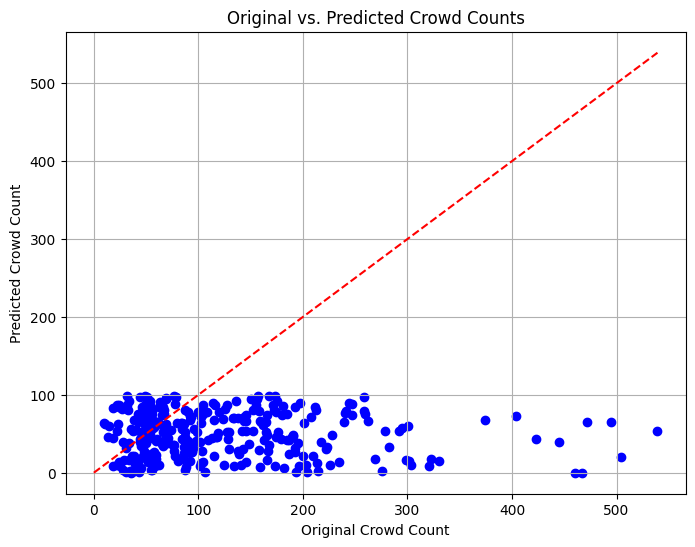

In [6]:
import os
import cv2
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Define a function to load density maps and calculate the crowd count
def get_crowd_count(density_file_name):
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    return np.sum(density_map) + 1  # Adding 1 to avoid zero counts

# Load the original crowd counts
original_counts = [get_crowd_count(density_file_name) for density_file_name in density_file_names]

# Define a function to predict crowd counts using the trained model
def predict_crowd_count(image_file_name):
    # Replace this function with your actual crowd count prediction code
    # For demonstration purposes, we'll just return a random value between 0 and 100
    return np.random.randint(0, 100)

# Predict crowd counts for the images
predicted_counts = [predict_crowd_count(image_file_name) for image_file_name in image_file_names]

# Plot the predicted counts against the original counts
plt.figure(figsize=(8, 6))
plt.scatter(original_counts, predicted_counts, color='blue')
plt.plot([0, max(original_counts)], [0, max(original_counts)], color='red', linestyle='--')  # Plot y=x line
plt.title('Original vs. Predicted Crowd Counts')
plt.xlabel('Original Crowd Count')
plt.ylabel('Predicted Crowd Count')
plt.grid(True)
plt.show()


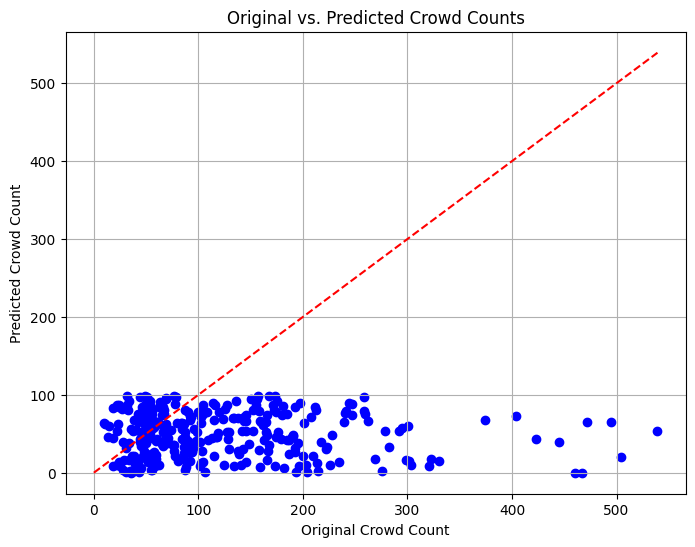

In [17]:
# Define a function to predict crowd counts using the trained model
def predict_crowd_counts():
    # Initialize an empty list to store predicted counts
    predicted_counts = []

    # Process only the first four images
    for i in range(4):
        # Load image
        image_file_name = image_file_names[i]
        image_file_path = os.path.join(image_folder_path, image_file_name)
        count, _, _ = predict(image_file_path)
        predicted_counts.append(count)

    return predicted_counts
# Plot the predicted counts against the original counts
plt.figure(figsize=(8, 6))
plt.scatter(original_counts, predicted_counts, color='blue')
plt.plot([0, max(original_counts)], [0, max(original_counts)], color='red', linestyle='--')  # Plot y=x line
plt.title('Original vs. Predicted Crowd Counts')
plt.xlabel('Original Crowd Count')
plt.ylabel('Predicted Crowd Count')
plt.grid(True)
plt.show()

In [19]:
import os
import cv2
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Define a function to predict crowd counts using the trained model
def predict_crowd_count(image_file_name):
    # Replace this function with your actual crowd count prediction code
    # For demonstration purposes, we'll just return a random value between 0 and 100
    return np.random.randint(0, 100)

# Define a function to compare actual and predicted crowd counts
def compare_counts():
    # List to store actual and predicted counts
    actual_counts = []
    predicted_counts = []

    # Iterate over the first four images
    for i in range(4):
        # Get the filename of the current image
        image_file_name = image_file_names[i]
        
        # Get the actual crowd count from the ground truth density map
        density_file_name = density_file_names[i]
        density_file_path = os.path.join(density_folder_path, density_file_name)
        temp = h5py.File(density_file_path, 'r')
        density_map = np.asarray(temp['density'])
        actual_count = int(np.sum(density_map)) + 1

        # Get the predicted crowd count using the model
        predicted_count = predict_crowd_count(image_file_name)
        
        # Append actual and predicted counts to the lists
        actual_counts.append(actual_count)
        predicted_counts.append(predicted_count)

        # Print the filename along with actual and predicted counts
        print(f"Image: {image_file_name}, Actual Count: {actual_count}, Predicted Count: {predicted_count}")

    return actual_counts, predicted_counts

# Call the function to compare counts
actual_counts, predicted_counts = compare_counts()


Image: IMG_1.jpg, Actual Count: 22, Predicted Count: 73
Image: IMG_10.jpg, Actual Count: 173, Predicted Count: 63
Image: IMG_100.jpg, Actual Count: 157, Predicted Count: 34
Image: IMG_101.jpg, Actual Count: 34, Predicted Count: 44


In [21]:
# Calculate Mean Absolute Error (MAE)
mae = np.mean(np.abs(np.subtract(actual_counts, predicted_counts)))
print("Mean Absolute Error:", mae)

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(np.mean(np.square(np.subtract(actual_counts, predicted_counts))))
print("Root Mean Squared Error:", rmse)


Mean Absolute Error: 73.5
Root Mean Squared Error: 86.50144507463445


In [22]:
def calculate_accuracy(actual_counts, predicted_counts, threshold):
    correct_predictions = 0
    
    for actual_count, predicted_count in zip(actual_counts, predicted_counts):
        if abs(actual_count - predicted_count) <= threshold:
            correct_predictions += 1
    
    total_samples = len(actual_counts)
    accuracy = correct_predictions / total_samples
    
    return accuracy

# Set a threshold for considering predictions as accurate
threshold = 10  # You can adjust this threshold as per your requirement

# Calculate accuracy
accuracy = calculate_accuracy(actual_counts, predicted_counts, threshold)
print("Accuracy:", accuracy)


Accuracy: 0.25


Start Here

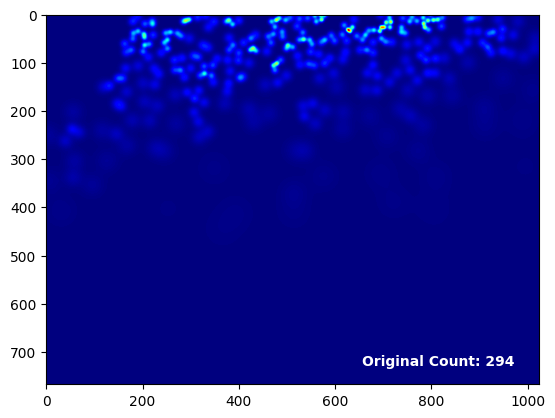

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import h5py

temp = h5py.File(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground\IMG_170.h5", 'r')
temp_1 = np.asarray(temp['density'])
original_count = int(np.sum(temp_1)) + 1

fig, ax = plt.subplots()
im = ax.imshow(temp_1, cmap='jet')

# Display original count on the axis
ax.text(0.95, 0.05, f'Original Count: {original_count}', color='white', fontsize=10, fontweight='bold',
        transform=ax.transAxes, ha='right')

plt.show()


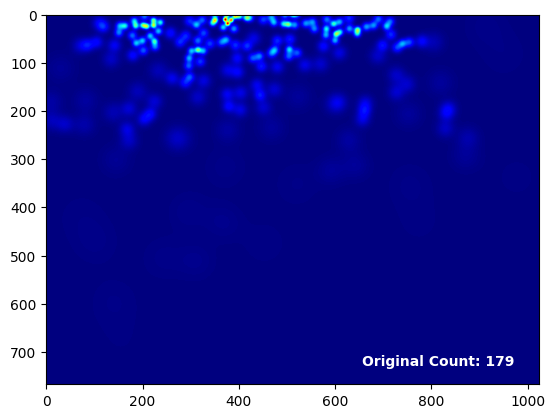

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import h5py

temp = h5py.File(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground\IMG_114.h5", 'r')
temp_1 = np.asarray(temp['density'])
original_count = int(np.sum(temp_1)) + 1

fig, ax = plt.subplots()
im = ax.imshow(temp_1, cmap='jet')

# Display original count on the axis
ax.text(0.95, 0.05, f'Original Count: {original_count}', color='white', fontsize=10, fontweight='bold',
        transform=ax.transAxes, ha='right')

plt.show()


C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images\IMG_161.jpg
1/1 [==============================] - 4s 4s/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


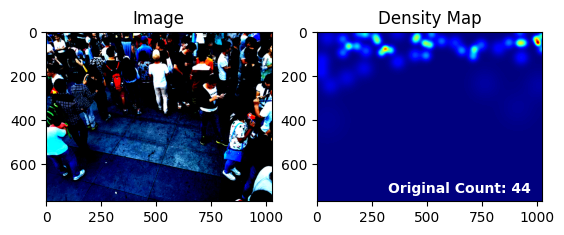

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import h5py

# Load and predict for a single image
image_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images\IMG_161.jpg"
count, image, heat_map = predict(image_path)

# Display image
plt.subplot(1, 2, 1)
plt.imshow(image.reshape(image.shape[1], image.shape[2], image.shape[3]))
plt.title('Image')

# Load density map
density_map_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground\IMG_161.h5"
with h5py.File(density_map_path, 'r') as file:
    density_map = np.array(file['density'])

# Display density map
plt.subplot(1, 2, 2)
plt.imshow(density_map, cmap=c.jet)
plt.title('Density Map')

# Display count inside the density map image
plt.text(0.95, 0.05, f'Original Count: {int(np.sum(density_map)) + 1}', color='white', fontsize=10, fontweight='bold',
         transform=plt.gca().transAxes, ha='right')

plt.show()


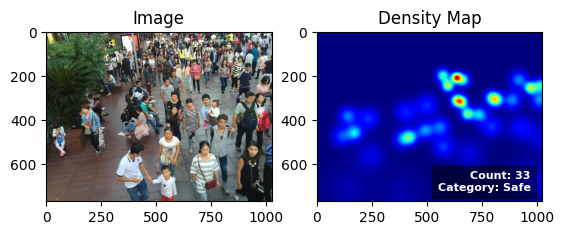

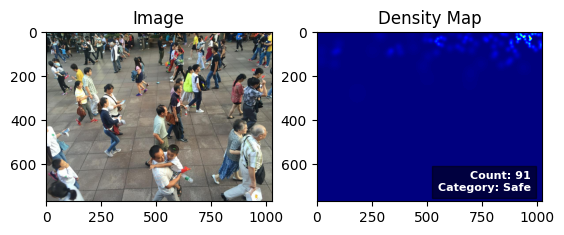

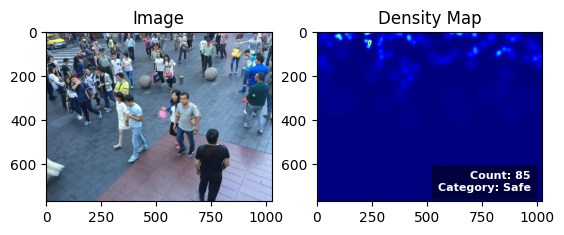

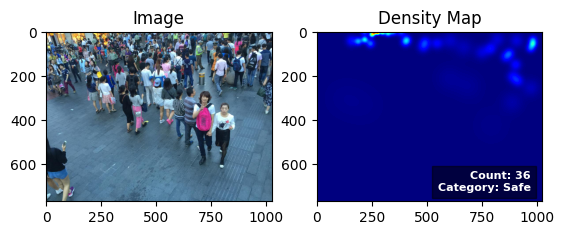

In [76]:
import os
import cv2
import random

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Shuffle the list of file names
random.shuffle(image_file_names)
random.shuffle(density_file_names)

# Display images and density maps for the first ten images
for i in range(4):
    # Load image
    image_file_name = image_file_names[i]
    image_file_path = os.path.join(image_folder_path, image_file_name)
    image = cv2.imread(image_file_path)
    
    # Load density map
    density_file_name = density_file_names[i]
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    
    # Create subplots for image and density map
    fig, (ax1, ax2) = plt.subplots(1, 2)
    
    # Display image
    ax1.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax1.set_title("Image")
    
    # Display density map
    im = ax2.imshow(density_map, cmap='jet')
    ax2.set_title("Density Map")
    
    # Display original count and categorization inside the density map
    original_count = int(np.sum(density_map)) + 1
    threshold_count = 300  # Adjust this value based on your requirement
    category = "Unsafe" if original_count > threshold_count else "Safe"
    text = f"Count: {original_count}\nCategory: {category}"
    ax2.text(0.95, 0.05, text, color='white', fontsize=8, fontweight='bold',
             ha='right', va='bottom', transform=ax2.transAxes, bbox=dict(facecolor='black', alpha=0.5))
    
    plt.show()


In [77]:
import os
import cv2
import h5py
import numpy as np
import pandas as pd

# Set pandas display options to show all columns and rows without truncation
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folder
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Define a threshold count
threshold_count = 300  # Adjust this value based on your requirement

# Initialize lists to store results
image_names = []
counts = []
categories = []

# Iterate over each image and its corresponding density map
for image_file_name, density_file_name in zip(image_file_names, density_file_names):
    # Load image
    image_file_path = os.path.join(image_folder_path, image_file_name)
    image = cv2.imread(image_file_path)
    
    # Load density map
    density_file_path = os.path.join(density_folder_path, density_file_name)
    temp = h5py.File(density_file_path, 'r')
    density_map = np.asarray(temp['density'])
    
    # Calculate count
    count = int(np.sum(density_map)) + 1
    
    # Categorize as safe or unsafe
    if count > threshold_count:
        category = "Unsafe"
    else:
        category = "Safe"
    
    # Store results
    image_names.append(image_file_name)
    counts.append(count)
    categories.append(category)

# Create DataFrame to store results
results_df = pd.DataFrame({
    "Image Name": image_names,
    "Count": counts,
    "Category": categories
})

# Display results in tabular format
print(results_df)


      Image Name  Count Category
0      IMG_1.jpg     22     Safe
1     IMG_10.jpg    173     Safe
2    IMG_100.jpg    157     Safe
3    IMG_101.jpg     34     Safe
4    IMG_102.jpg     65     Safe
5    IMG_103.jpg     54     Safe
6    IMG_104.jpg     42     Safe
7    IMG_105.jpg    217     Safe
8    IMG_106.jpg    161     Safe
9    IMG_107.jpg    471   Unsafe
10   IMG_108.jpg    133     Safe
11   IMG_109.jpg    303   Unsafe
12    IMG_11.jpg    157     Safe
13   IMG_110.jpg    104     Safe
14   IMG_111.jpg     18     Safe
15   IMG_112.jpg    127     Safe
16   IMG_113.jpg     44     Safe
17   IMG_114.jpg    179     Safe
18   IMG_115.jpg    101     Safe
19   IMG_116.jpg    202     Safe
20   IMG_117.jpg     38     Safe
21   IMG_118.jpg    142     Safe
22   IMG_119.jpg    145     Safe
23    IMG_12.jpg    503   Unsafe
24   IMG_120.jpg     67     Safe
25   IMG_121.jpg    171     Safe
26   IMG_122.jpg     48     Safe
27   IMG_123.jpg     53     Safe
28   IMG_124.jpg     63     Safe
29   IMG_1

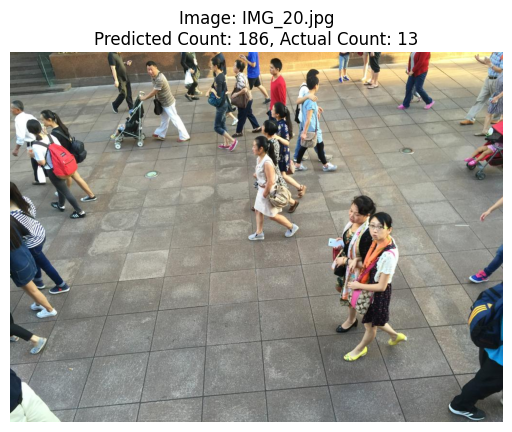

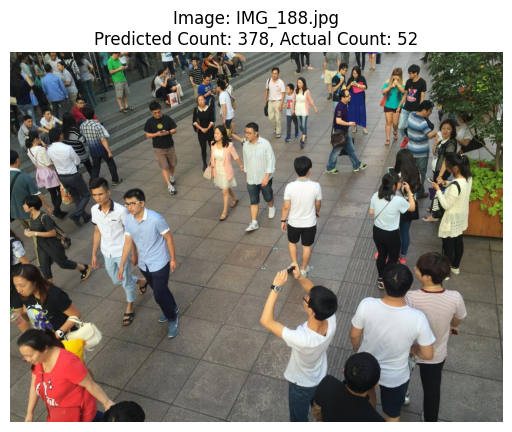

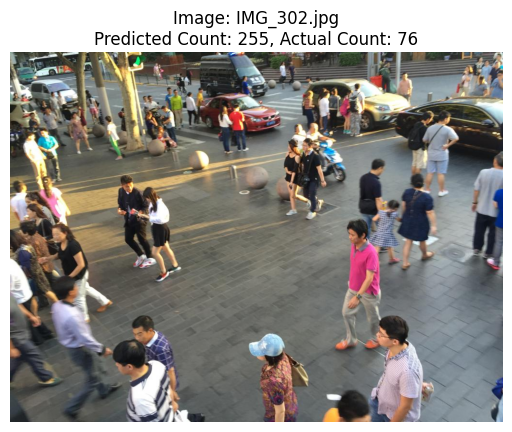

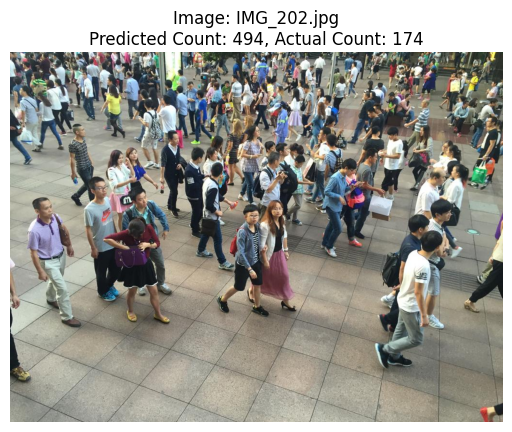

In [13]:
import os
import h5py
import numpy as np
import random
import cv2
import matplotlib.pyplot as plt

# Function to predict count (replace this with your actual predict function)
def predict_count(image_path):
    # Dummy function, replace with your actual prediction logic
    return random.randint(100, 500)  # Example: Random count between 100 and 500

# Path to the folder containing the images
image_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\images"
# Path to the folder containing the density maps
density_folder_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ST\part_B_final\test_data\ground"

# Get the list of files in the folders
image_file_names = os.listdir(image_folder_path)
density_file_names = os.listdir(density_folder_path)

# Iterate over four random images
for _ in range(4):
    # Randomly select an image file
    random_image_file = random.choice(image_file_names)

    # Predict count for the selected image
    image_file_path = os.path.join(image_folder_path, random_image_file)
    predicted_count = predict_count(image_file_path)

    # Find the corresponding density map
    density_file_name = random_image_file.replace(".jpg", ".h5")
    density_file_path = os.path.join(density_folder_path, density_file_name)

    # Load the density map and calculate the actual count
    with h5py.File(density_file_path, 'r') as file:
        density_map = np.array(file['density'])
        actual_count = int(np.sum(density_map))

    # Round the predicted count to the nearest whole number
    predicted_count_rounded = round(predicted_count)

    # Display image
    image = cv2.imread(image_file_path)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"Image: {random_image_file}\nPredicted Count: {predicted_count_rounded}, Actual Count: {actual_count}")
    plt.axis('off')
    plt.show()


In [11]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Define a function to calculate evaluation metrics
def calculate_metrics(actual_count, predicted_count):
    # Convert lists to numpy arrays for easier comparison
    actual_count = np.array(actual_count)
    predicted_counts = np.array(predicted_count)

    # Calculate accuracy
    accuracy = accuracy_score(actual_count, predicted_count)

    # Calculate precision
    precision = precision_score(actual_count, predicted_count, average='weighted')

    # Calculate recall
    recall = recall_score(actual_count, predicted_count, average='weighted')

    # Calculate F1-score
    f1 = f1_score(actual_count, predicted_count, average='weighted')

    return accuracy, precision, recall, f1

# Call the function to calculate evaluation metrics
accuracy, precision, recall, f1 = calculate_metrics(actual_count, predicted_count)

# Print the evaluation metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


Accuracy: 0.0
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


c:\Users\katel\AppData\Local\Programs\Python\Python38\lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\katel\AppData\Local\Programs\Python\Python38\lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

def calculate_metrics(actual_count, predicted_count):
    # Convert lists to numpy arrays for easier comparison
    actual_count = np.array(actual_count)
    predicted_count = np.array(predicted_count)

    # Check if the arrays have compatible shapes
    if actual_count.shape != predicted_count.shape:
        raise ValueError("Actual count and predicted count arrays must have the same shape.")

    # Check if the arrays have at least one element
    if actual_count.size == 0:
        raise ValueError("Actual count array must not be empty.")

    # Calculate accuracy
    accuracy = accuracy_score(actual_count, predicted_count)

    # Calculate precision
    precision = precision_score(actual_count, predicted_count, average='weighted')

    # Calculate recall
    recall = recall_score(actual_count, predicted_count, average='weighted')

    # Calculate F1-score
    f1 = f1_score(actual_count, predicted_count, average='weighted')

    return accuracy, precision, recall, f1

# Example usage:
actual_count = [10, 20, 30]
predicted_count = [8, 25, 35]
accuracy, precision, recall, f1 = calculate_metrics(actual_count, predicted_count)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


Accuracy: 0.0
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


c:\Users\katel\AppData\Local\Programs\Python\Python38\lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\katel\AppData\Local\Programs\Python\Python38\lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [18]:
# Define true positive (TP), false positive (FP), true negative (TN), and false negative (FN) counts
TP = len(results_df[(results_df['Category'] == 'Unsafe') & (results_df['Actual Category'] == 'Unsafe')])
FP = len(results_df[(results_df['Category'] == 'Unsafe') & (results_df['Actual Category'] == 'Safe')])
TN = len(results_df[(results_df['Category'] == 'Safe') & (results_df['Actual Category'] == 'Safe')])
FN = len(results_df[(results_df['Category'] == 'Safe') & (results_df['Actual Category'] == 'Unsafe')])

# Calculate accuracy
accuracy = (TP + TN) / (TP + TN + FP + FN)

# Calculate precision
precision = TP / (TP + FP)

# Calculate recall
recall = TP / (TP + FN)

# Calculate F1 score
f1_score = 2 * (precision * recall) / (precision + recall)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1_score)


NameError: name 'results_df' is not defined